In [1]:
from ultralytics import YOLO

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
import numpy as np

In [2]:
model_26m = YOLO('yolo26m.pt')

In [3]:
metrics = model_26m.val(
    data='../data/validation/coco.yaml', 
    split='val',
    save=False, 
    device='cpu', 
    verbose=False,
    classes=[15]
)

Ultralytics 8.4.176  Python-3.12.10 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12450H)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 389.4±203.0 MB/s, size: 181.0 KB)
val: Scanning C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\validation\val2017... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000 366.1it/s 13.7s0.1s
val: New cache created: C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\validation\val2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 313/313 6.0s/it 31:324.2ss1
                   all       5000        202      0.942      0.891      0.939      0.798
Speed: 0.9ms preprocess, 366.2ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\detect\val


<Axes: >

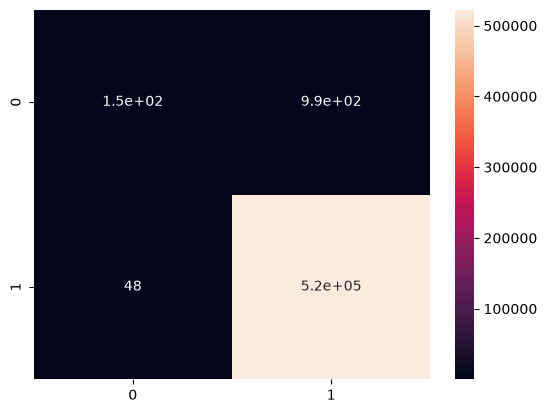

In [16]:
cm = np.array(metrics.confusion_matrix.matrix)
c = 15  # índice de "cat"

TP = cm[c, c]
FN = cm[c, :].sum() - TP
FP = cm[:, c].sum() - TP
TN = cm.sum() - TP - FN - FP

cm_cat = np.array([[TP, FN],
                   [FP, TN]])
sns.heatmap(cm_cat, annot=True)